# GO 的真实面貌：从本体到基因相似度

**GO 2026-07-26 · 人类 UniProt 注释 · 可重新运行的探索概览**

沿着一条链条阅读：**功能概念 → 有类型的关系 → 功能注释与证据 → 基因产物的功能集合 → 相似度表示**。

这份 notebook 回答六个问题：
1. BP、MF、CC 各有多少概念？本体包含哪些关系？
2. GO 的层级有多深？为什么它是一张图？
3. 注释主要依据哪些证据？记录数与功能数有什么区别？
4. 不同基因产物的注释覆盖有多不均匀？
5. 一个真实基因产物具体被注释了什么？
6. 注释向祖先传播后，基因相似度会怎样变化？

图表直接从下载的 OBO/GAF 重算，运行中无需联网。图像和统计表另存到 `outputs/notebooks/01_go_overview/`。

## 0 · 环境与可修改参数

在 IDE 中选择项目 `.venv/bin/python` 作为 kernel，然后 **Run All**。
下面可改示例对象、相似度 aspect 和证据代码，再从头运行。默认选择 TP53 和 BP，使用全部证据代码。

In [1]:
from pathlib import Path
from collections import Counter, defaultdict
from dataclasses import asdict
from functools import lru_cache
from textwrap import fill
import hashlib
import json
import os
import sys

def find_project_root():
    for candidate in (Path.cwd(), *Path.cwd().parents):
        if (candidate / "configs/data_manifest.human.2026-07-26.json").is_file():
            return candidate
    raise FileNotFoundError("请从本项目根目录或 notebooks/ 启动 notebook。")

ROOT = find_project_root()
sys.path.insert(0, str(ROOT / "src"))
OUT = ROOT / "outputs/notebooks/01_go_overview"
OUT.mkdir(parents=True, exist_ok=True)
os.environ.setdefault("MPLCONFIGDIR", str(OUT / ".matplotlib"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager, ticker
from matplotlib.lines import Line2D
import networkx as nx
from IPython.display import Markdown, display
from go_enrichment.ontology import Ontology, jaccard
from go_enrichment.annotations import read_gaf

MANIFEST = ROOT / "configs/data_manifest.human.2026-07-26.json"
EXAMPLE_OBJECT_ID = "UniProtKB:P04637"  # TP53
SIMILARITY_ASPECT = "biological_process"  # 也可改为 molecular_function / cellular_component
EVIDENCE_CODES = None  # 例如 {"IDA", "IMP", "IGI"}；None 表示全部代码
FOCAL_TERM_ID = "GO:0006281"  # DNA repair
ROOT_IDS = {"GO:0008150", "GO:0003674", "GO:0005575"}
ASPECTS = {"biological_process": "BP", "molecular_function": "MF", "cellular_component": "CC"}
PALETTE = {"BP": "#247B8A", "MF": "#DF9451", "CC": "#6E71A8"}
# 仅合并这里明确列出的 gene-product relation；上游作用等记录仍计入全局原始统计。
PROJECTION_RELATIONS = {
    "biological_process": {"involved_in"},
    "molecular_function": {"enables"},
    "cellular_component": {"located_in", "is_active_in", "part_of"},
}[SIMILARITY_ASPECT]

available_fonts = {font.name for font in font_manager.fontManager.ttflist}
plt.rcParams.update({
    "font.family": "Noto Sans CJK JP" if "Noto Sans CJK JP" in available_fonts else "DejaVu Sans",
    "font.size": 10, "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "bold", "figure.dpi": 110, "savefig.dpi": 160,
    "axes.unicode_minus": False, "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.axisbelow": True,
})
pd.set_option("display.max_colwidth", 95)
pd.set_option("display.max_rows", 20)

def save_figure(fig, name):
    fig.savefig(OUT / f"{name}.png", bbox_inches="tight")
    fig.savefig(OUT / f"{name}.svg", bbox_inches="tight")
    plt.show()
    plt.close(fig)

print(f"示例：{EXAMPLE_OBJECT_ID} | 相似度：{ASPECTS[SIMILARITY_ASPECT]} | relation：{sorted(PROJECTION_RELATIONS)}")

示例：UniProtKB:P04637 | 相似度：BP | relation：['involved_in']


## 1 · 读取真实文件与固定快照

先核对 SHA256，再完整解析。全局图表保留全部证据和否定记录的统计；`EVIDENCE_CODES` 只影响后面的功能集合与相似度。

In [2]:
manifest = json.loads(MANIFEST.read_text())
files = []
for section in ("ontology", "annotations"):
    entry = manifest[section]
    path = ROOT / entry["local_path"]
    digest = hashlib.sha256()
    with path.open("rb") as handle:
        for block in iter(lambda: handle.read(1024 * 1024), b""):
            digest.update(block)
    assert digest.hexdigest() == entry["sha256"], f"校验和变化：{path.name}"
    files.append({"对象": section, "文件": path.name, "GO 版本": entry["release"],
                  "大小 (MiB)": round(path.stat().st_size / 1024**2, 2), "SHA256": "通过"})
display(pd.DataFrame(files))

ontology = Ontology.read(ROOT / manifest["ontology"]["local_path"])
active = {key: term for key, term in ontology.terms.items() if not term.obsolete}
assert ontology.metadata["data-version"] == [f"releases/{manifest['ontology']['release']}"]

objects = {}  # GAF DB Object ID -> display symbol；不把 symbol 当连接键
memberships = defaultdict(set)  # 全部正记录对应的去重 term 集合
projection_memberships = defaultdict(set)  # 指定 aspect / relation / evidence 的正集合
record_counts = Counter()
evidence_counts = Counter()
aspect_record_counts = Counter()
relation_counts = Counter()
negative_counts = Counter()
example_records = []
total_records = 0
for record in read_gaf(ROOT / manifest["annotations"]["local_path"]):
    assert record.term_id in active, f"未知或 obsolete term：{record.term_id}"
    assert record.taxon.split("|")[0] == manifest["annotations"]["taxon"]
    total_records += 1
    objects[record.object_id] = record.symbol
    record_counts[record.object_id] += 1
    evidence_counts[record.evidence] += 1
    aspect_record_counts[record.aspect] += 1
    relation_counts[record.relation] += 1
    if record.object_id == EXAMPLE_OBJECT_ID:
        example_records.append(asdict(record))
    if record.negated:
        negative_counts[record.object_id] += 1
        continue
    memberships[record.object_id].add(record.term_id)
    if (active[record.term_id].namespace == SIMILARITY_ASPECT
        and record.relation in PROJECTION_RELATIONS
        and (EVIDENCE_CODES is None or record.evidence in EVIDENCE_CODES)):
        projection_memberships[record.object_id].add(record.term_id)

assert sum(evidence_counts.values()) == total_records
assert EXAMPLE_OBJECT_ID in objects, "示例 ID 不在本文件中，请检查参数。"
print(f"解析完成：{len(active):,} 个有效 term；{total_records:,} 条记录；{len(objects):,} 个 DB Object ID。")
print(f"NOT 记录：{sum(negative_counts.values()):,}；不进入后续正注释投影。")

,对象,文件,GO 版本,大小 (MiB),SHA256
0,ontology,go-basic.obo,2026-07-26,30.73,通过
1,annotations,HUMAN-uniprot.gaf.gz,2026-07-26,11.55,通过


解析完成：38,092 个有效 term；910,476 条记录；38,902 个 DB Object ID。
NOT 记录：1,497；不进入后续正注释投影。


## 2 · GO 由什么组成？

左图是**概念数量**，右图是 active term 发出的**本体关系数量**。它们和基因数量、注释记录数量分别计数。
BP 描述过程，MF 描述分子活动，CC 描述细胞结构及复合体。

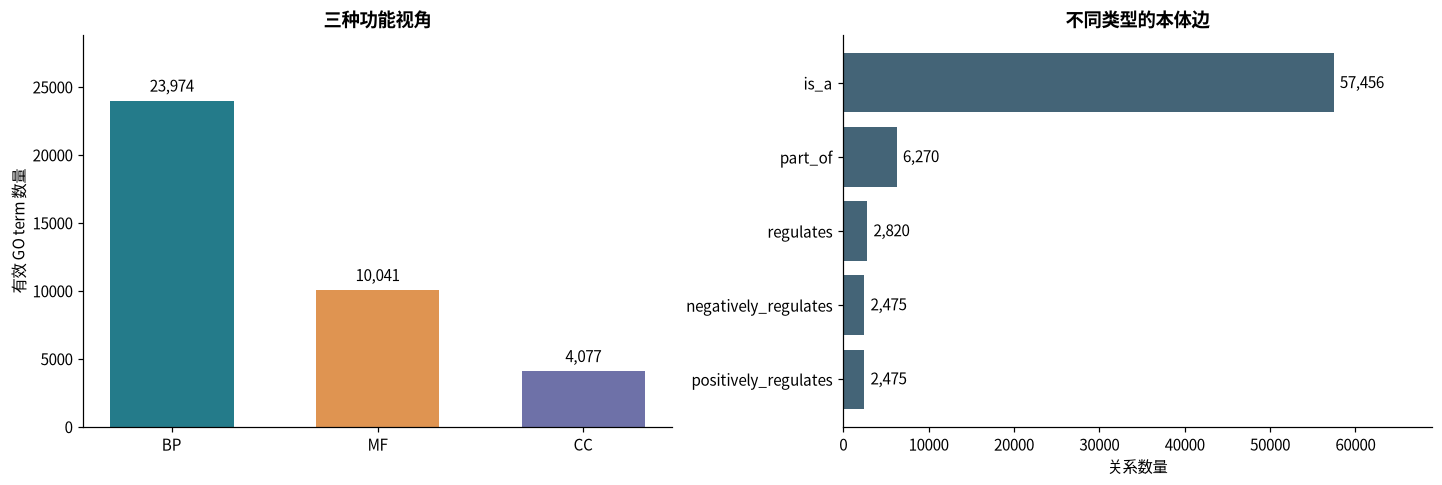

In [3]:
term_counts = Counter(ASPECTS[t.namespace] for t in active.values())
edge_counts = Counter(relation for t in active.values() for relation, target in t.edges if target in active)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3), layout="constrained")
labels = list(PALETTE)
bars = axes[0].bar(labels, [term_counts[x] for x in labels], color=[PALETTE[x] for x in labels], width=0.6)
axes[0].bar_label(bars, labels=[f"{term_counts[x]:,}" for x in labels], padding=4)
axes[0].set(title="三种功能视角", ylabel="有效 GO term 数量", ylim=(0, max(term_counts.values()) * 1.2))
edge_items = edge_counts.most_common()[::-1]
bars = axes[1].barh([r for r, _ in edge_items], [n for _, n in edge_items], color="#446477")
axes[1].bar_label(bars, labels=[f"{n:,}" for _, n in edge_items], padding=4)
axes[1].set(title="不同类型的本体边", xlabel="关系数量", xlim=(0, max(edge_counts.values()) * 1.2))
save_figure(fig, "01_ontology_composition")

## 3 · 层级有多深？为什么不是一棵树？

这里仅沿 **`is_a`** 计算到各 aspect 根节点的最短路径长度。它是一个明确的结构指标；GO 中同一 term 可以有多个 parent，因而还可能存在更长路径。
右图统计非根 term 的直接 `is_a` parent 数量。

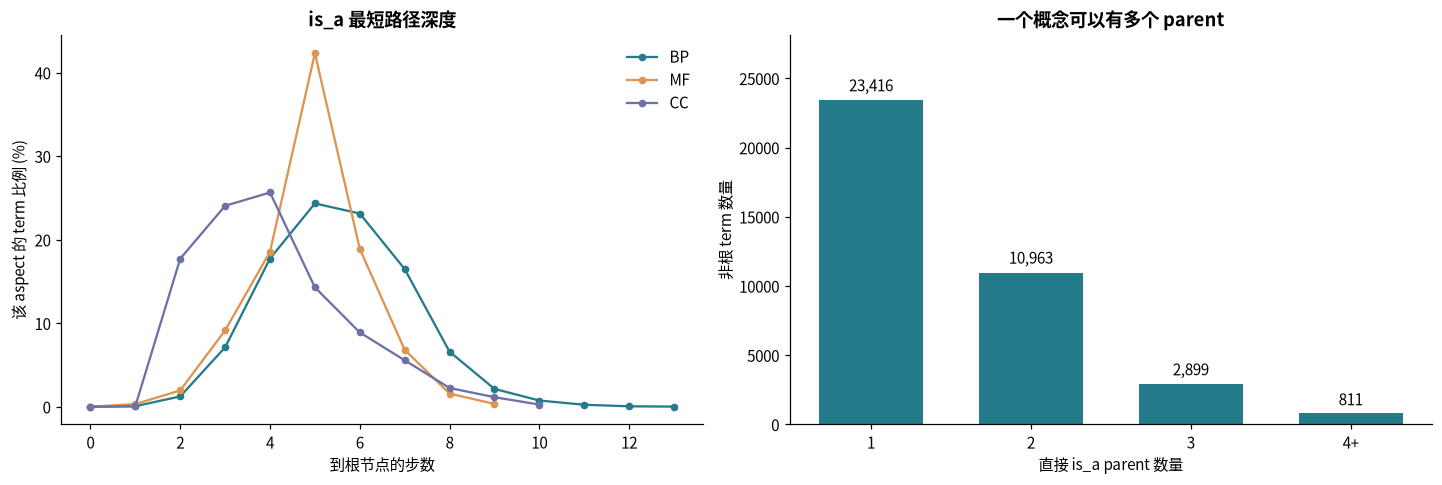

14,673 个非根 term 有多个 is_a parent，占 38.5%。


In [4]:
isa = nx.DiGraph()
isa.add_nodes_from(active)
isa.add_edges_from((key, target) for key, term in active.items()
                  for relation, target in term.edges if relation == "is_a" and target in active)
assert nx.is_directed_acyclic_graph(isa)
root_by_aspect = {"BP": "GO:0008150", "MF": "GO:0003674", "CC": "GO:0005575"}
depth_rows = []
for aspect, root_id in root_by_aspect.items():
    distances = nx.single_source_shortest_path_length(isa.reverse(copy=False), root_id)
    depth_rows.extend({"term_id": key, "aspect": aspect, "shortest_is_a_depth": depth}
                      for key, depth in distances.items() if ASPECTS[active[key].namespace] == aspect)
depth_df = pd.DataFrame(depth_rows)
assert len(depth_df) == len(active), "存在无法经 is_a 到达对应根节点的有效 term。"
parent_counts = Counter(isa.out_degree(key) for key in active if key not in ROOT_IDS)
parent_groups = {"1": parent_counts[1], "2": parent_counts[2], "3": parent_counts[3],
                 "4+": sum(n for parents, n in parent_counts.items() if parents >= 4)}
assert sum(parent_groups.values()) == len(active) - len(ROOT_IDS)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3), layout="constrained")
for aspect in PALETTE:
    grouped = depth_df.loc[depth_df.aspect == aspect, "shortest_is_a_depth"].value_counts(normalize=True).sort_index()
    axes[0].plot(grouped.index, grouped.values * 100, marker="o", markersize=4, label=aspect, color=PALETTE[aspect])
axes[0].set(title="is_a 最短路径深度", xlabel="到根节点的步数", ylabel="该 aspect 的 term 比例 (%)")
axes[0].xaxis.set_major_locator(ticker.MaxNLocator(integer=True))
axes[0].legend(frameon=False)
bars = axes[1].bar(parent_groups.keys(), parent_groups.values(), color="#247B8A", width=0.65)
axes[1].bar_label(bars, labels=[f"{n:,}" for n in parent_groups.values()], padding=4)
axes[1].set(title="一个概念可以有多个 parent", xlabel="直接 is_a parent 数量", ylabel="非根 term 数量",
            ylim=(0, max(parent_groups.values()) * 1.2))
save_figure(fig, "02_hierarchy_depth")
multi_parent = sum(n for degree, n in parent_counts.items() if degree >= 2)
print(f"{multi_parent:,} 个非根 term 有多个 is_a parent，占 {multi_parent / (len(active) - 3):.1%}。")

## 4 · 放大看一个功能区域：DNA repair

下面绘制焦点 term、两步内的 `is_a` / `part_of` 祖先、最多五个直接下位 term，以及最多两个直接调控该 term 的概念。
**箭头表示原始 OBO 中的 child/source → parent/target**，颜色表示关系类型。图是局部选取，图下报告省略数量。

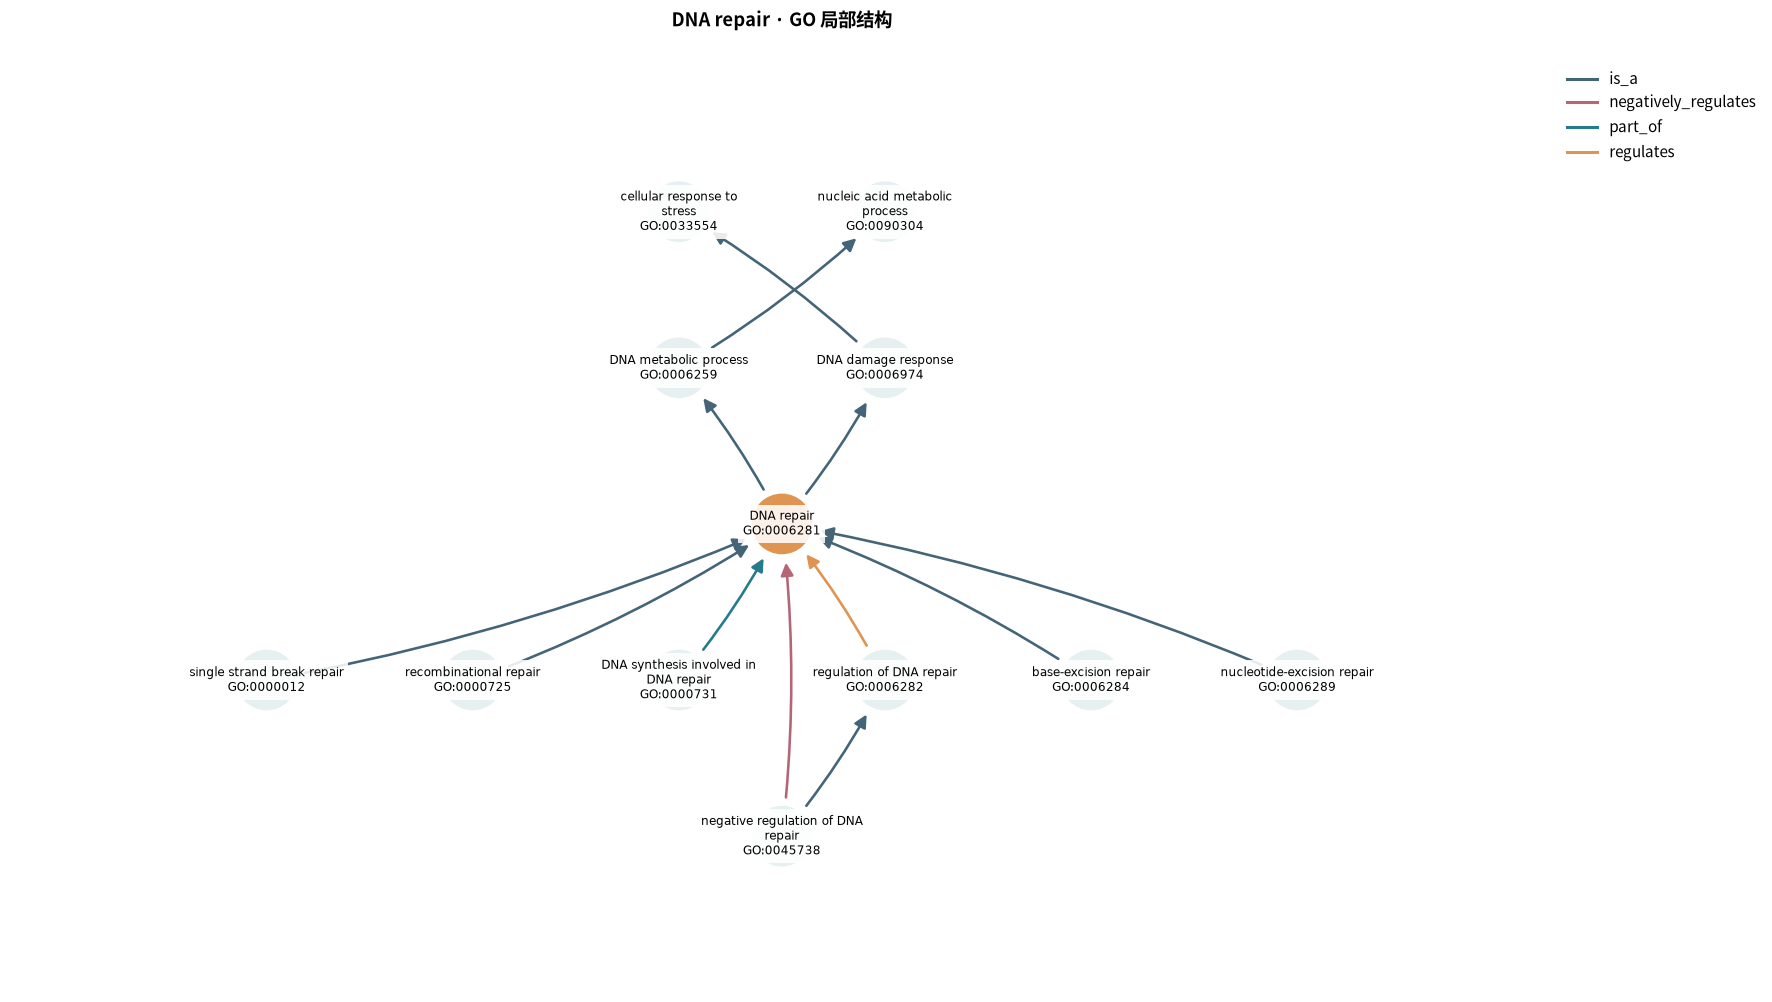

展示 12 个节点、12 条边；焦点直接下位 term 共 18 个，展示 5 个；调控 term 共 3 个，展示 2 个。


In [5]:
focus = ontology.resolve(FOCAL_TERM_ID).id
assert focus in active
shown = {focus}
frontier = {focus}
for _ in range(2):
    frontier = {target for key in frontier for relation, target in active[key].edges
                if relation in {"is_a", "part_of"} and target in active}
    shown |= frontier
children = sorted(key for key, term in active.items()
                  if any(target == focus and relation in {"is_a", "part_of"} for relation, target in term.edges))
regulators = sorted(key for key, term in active.items()
                    if any(target == focus and "regulates" in relation for relation, target in term.edges))
shown.update(children[:5])
shown.update(regulators[:2])
local = nx.MultiDiGraph()
local.add_nodes_from(sorted(shown))
local.add_edges_from((key, target, {"relation": relation}) for key in sorted(shown)
                     for relation, target in active[key].edges if target in shown)
layout_graph = nx.DiGraph(local).reverse(copy=True)
assert nx.is_directed_acyclic_graph(layout_graph)
positions = {}
for level, generation in enumerate(nx.topological_generations(layout_graph)):
    group = sorted(generation)
    for index, key in enumerate(group):
        positions[key] = (3.0 * (index - (len(group) - 1) / 2), -1.8 * level)
relation_colors = {"is_a": "#446477", "part_of": "#247B8A", "regulates": "#DF9451",
                   "positively_regulates": "#6D9B56", "negatively_regulates": "#B56676"}
fig, ax = plt.subplots(figsize=(16, 9), layout="constrained")
nx.draw_networkx_nodes(local, positions, ax=ax, node_size=1700,
                       node_color=["#DF9451" if key == focus else "#E7F0F1" for key in local],
                       edgecolors="#FFFFFF", linewidths=1.5)
for relation in sorted({data["relation"] for _, _, data in local.edges(data=True)}):
    selected = [(left, right, key) for left, right, key, data in local.edges(keys=True, data=True) if data["relation"] == relation]
    nx.draw_networkx_edges(local, positions, edgelist=selected, ax=ax,
                           edge_color=relation_colors.get(relation, "#888888"), width=1.7,
                           arrowsize=17, node_size=2600, connectionstyle="arc3,rad=0.06")
labels = {key: fill(active[key].name, 26) + "\n" + key for key in local}
nx.draw_networkx_labels(local, positions, labels=labels, ax=ax, font_size=8,
                        bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.88, "pad": 3})
handles = [Line2D([0], [0], color=relation_colors.get(r, "#888888"), lw=2, label=r)
           for r in sorted({data["relation"] for _, _, data in local.edges(data=True)})]
ax.legend(handles=handles, frameon=False, loc="upper left", bbox_to_anchor=(1.0, 1.0))
ax.set_title(f"{active[focus].name} · GO 局部结构", pad=20)
ax.margins(0.18)
ax.axis("off")
save_figure(fig, "03_local_ontology_graph")
print(f"展示 {local.number_of_nodes()} 个节点、{local.number_of_edges()} 条边；焦点直接下位 term 共 {len(children)} 个，展示 {min(5, len(children))} 个；调控 term 共 {len(regulators)} 个，展示 {min(2, len(regulators))} 个。")

## 5 · 人类注释的证据从哪里来？

统计单位是**原始 annotation record**，包括 NOT。一条 object–term 关联可以有多条不同证据或来源记录。
证据代码标明支持方式；图中比例表达数据来源组成，不作为统一的置信度分数。

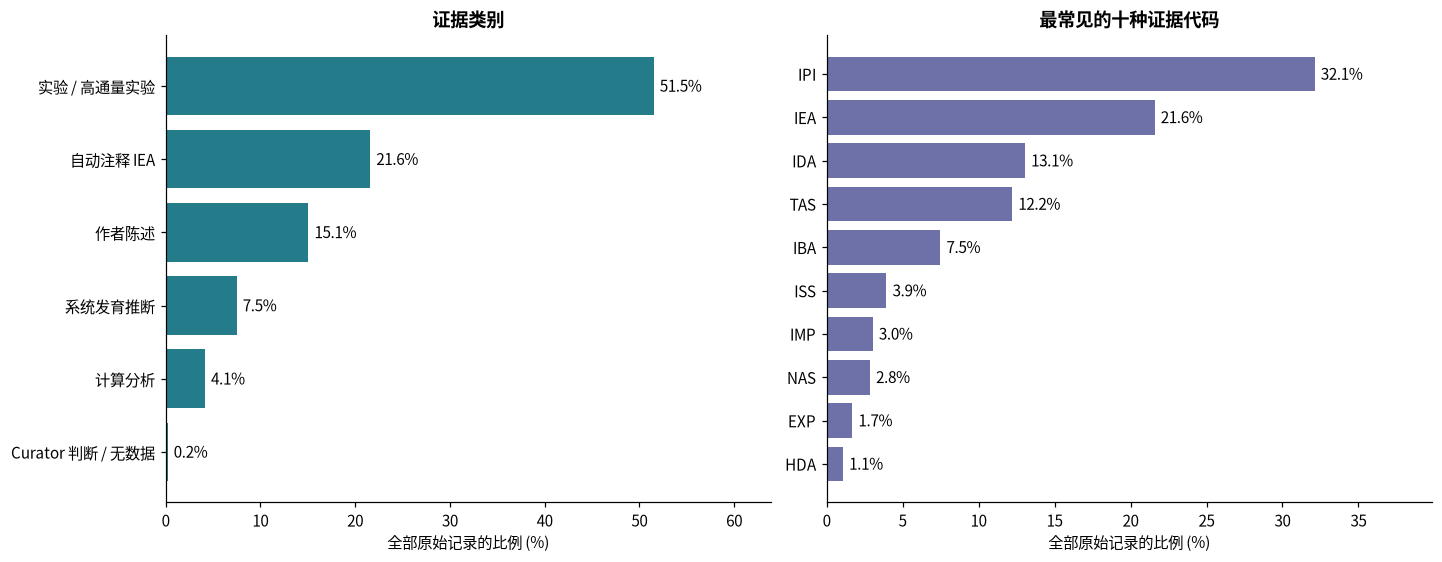

In [6]:
evidence_groups = {
    "实验 / 高通量实验": {"EXP", "IDA", "IPI", "IMP", "IGI", "IEP", "HTP", "HDA", "HMP", "HGI", "HEP"},
    "系统发育推断": {"IBA", "IBD", "IKR", "IRD"},
    "计算分析": {"ISS", "ISO", "ISA", "ISM", "IGC", "RCA"},
    "作者陈述": {"TAS", "NAS"},
    "Curator 判断 / 无数据": {"IC", "ND"},
    "自动注释 IEA": {"IEA"},
}
known_codes = set().union(*evidence_groups.values())
assert set(evidence_counts) <= known_codes
group_counts = {name: sum(evidence_counts[c] for c in codes) for name, codes in evidence_groups.items()}
assert sum(group_counts.values()) == total_records
fig, axes = plt.subplots(1, 2, figsize=(13, 5), layout="constrained")
for ax, items, title, color in [
    (axes[0], sorted(group_counts.items(), key=lambda x: x[1]), "证据类别", "#247B8A"),
    (axes[1], evidence_counts.most_common(10)[::-1], "最常见的十种证据代码", "#6E71A8"),
]:
    bars = ax.barh([name for name, n in items], [100 * n / total_records for name, n in items], color=color)
    ax.bar_label(bars, labels=[f"{n / total_records:.1%}" for _, n in items], padding=4)
    ax.set(title=title, xlabel="全部原始记录的比例 (%)", xlim=(0, max(n / total_records * 100 for _, n in items) * 1.24))
save_figure(fig, "04_evidence_sources")
evidence_df = pd.DataFrame(evidence_counts.most_common(), columns=["evidence_code", "records"])
evidence_df["percent"] = evidence_df.records / total_records * 100
evidence_df.to_csv(OUT / "evidence_counts.csv", index=False)

## 6 · 覆盖分布：一个对象有多少功能注释？

每个 DB Object ID 内去重 term，NOT 单独处理。左图的每个点表示“拥有不超过 x 个直接 term 的对象比例”。
右图展示全部 aspect 合计的覆盖档位。

分母为**这份 GAF 中出现的 DB Object ID**，尚未映射成 HGNC / Ensembl gene，也不包括文件里未出现的人类基因。
这里保留所有正注释关系；后面的相似度采用第 0 节明示的关系与证据策略。

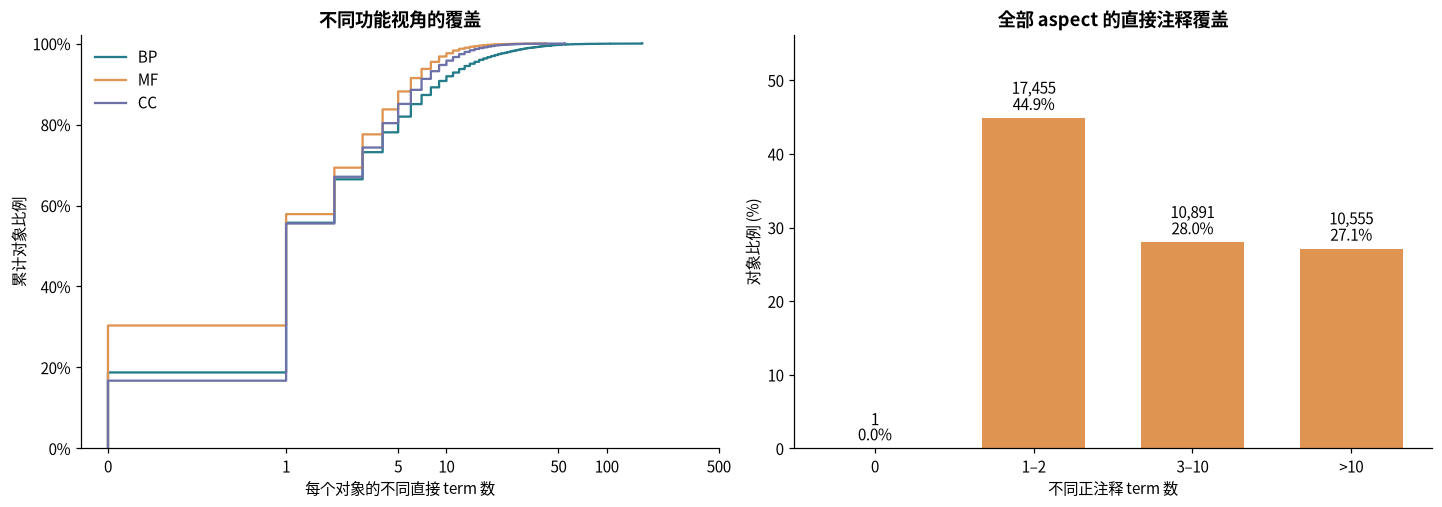

,positive_terms,BP,MF,CC
分位点,,,,
0.00,0.0,0.0,0.0,0.0
0.25,2.0,1.0,0.0,1.0
0.50,4.0,1.0,1.0,1.0
0.75,11.0,4.0,3.0,4.0
0.95,30.0,14.0,8.0,10.0
1.00,221.0,167.0,42.0,55.0


In [7]:
aspect_term_sets = {aspect: {key for key, t in active.items() if ASPECTS[t.namespace] == aspect} for aspect in PALETTE}
coverage_rows = []
for object_id in sorted(objects):
    terms = memberships.get(object_id, set())
    coverage_rows.append({"object_id": object_id, "symbol": objects[object_id],
                          "records": record_counts[object_id], "positive_terms": len(terms),
                          **{aspect: len(terms & keys) for aspect, keys in aspect_term_sets.items()}})
coverage = pd.DataFrame(coverage_rows)
bins = {"0": int((coverage.positive_terms == 0).sum()),
        "1–2": int(coverage.positive_terms.between(1, 2).sum()),
        "3–10": int(coverage.positive_terms.between(3, 10).sum()),
        ">10": int((coverage.positive_terms > 10).sum())}
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), layout="constrained")
for aspect in PALETTE:
    values = np.sort(coverage[aspect].to_numpy())
    axes[0].step(values, np.arange(1, len(values) + 1) / len(values), where="post", label=aspect, color=PALETTE[aspect])
axes[0].set_xscale("symlog", linthresh=1)
axes[0].set_xticks([0, 1, 5, 10, 50, 100, 500], labels=["0", "1", "5", "10", "50", "100", "500"])
axes[0].yaxis.set_major_formatter(ticker.PercentFormatter(1))
axes[0].set(title="不同功能视角的覆盖", xlabel="每个对象的不同直接 term 数", ylabel="累计对象比例", ylim=(0, 1.02))
axes[0].legend(frameon=False)
bars = axes[1].bar(bins.keys(), [100 * n / len(coverage) for n in bins.values()], color="#DF9451", width=0.65)
axes[1].bar_label(bars, labels=[f"{n:,}\n{n / len(coverage):.1%}" for n in bins.values()], padding=4)
axes[1].set(title="全部 aspect 的直接注释覆盖", xlabel="不同正注释 term 数", ylabel="对象比例 (%)",
            ylim=(0, max(bins.values()) / len(coverage) * 100 * 1.25))
save_figure(fig, "05_annotation_coverage")
display(coverage[["positive_terms", "BP", "MF", "CC"]].quantile([0, 0.25, 0.5, 0.75, 0.95, 1]).rename_axis("分位点"))
coverage.to_csv(OUT / "object_coverage.csv", index=False)

## 7 · 具体看一个对象：TP53（默认）

左图比较每个 aspect 的原始记录数与去重正注释 term 数；右图查看该对象的主要证据来源。
下表给出所选相似度 aspect 中的一部分直接功能，保留 relation、否定标记、证据及引用数量。

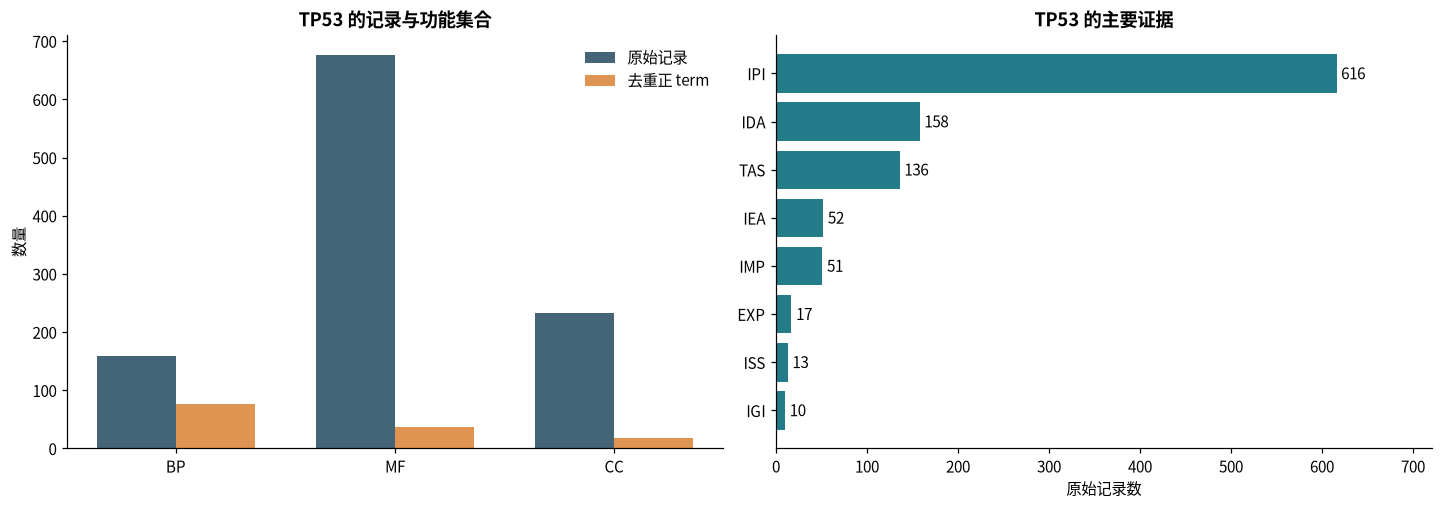

,GO ID,name,aspect,relation,NOT,records,evidence,references
0,GO:0045944,positive regulation of transcription by RNA polymerase II,BP,involved_in,False,13,"IBA, IDA, IMP, ISS",13
1,GO:0030330,"DNA damage response, signal transduction by p53 class mediator",BP,involved_in,False,7,"IDA, IMP",6
2,GO:0010628,positive regulation of gene expression,BP,involved_in,False,5,"IDA, IMP, ISS",5
3,GO:0045892,negative regulation of DNA-templated transcription,BP,involved_in,False,5,"IDA, IEA, IMP, NAS",5
4,GO:0045893,positive regulation of DNA-templated transcription,BP,involved_in,False,5,"IDA, IEA, IMP",5
5,GO:1902895,positive regulation of miRNA transcription,BP,involved_in,False,5,"IDA, IGI, IMP",3
6,GO:0006974,DNA damage response,BP,involved_in,False,4,"IDA, IMP",4
7,GO:0008285,negative regulation of cell population proliferation,BP,involved_in,False,4,"IDA, IEA, IMP, ISS",4
8,GO:0042771,intrinsic apoptotic signaling pathway in response to DNA damage by p53 class mediator,BP,involved_in,False,4,"IBA, IDA, IEA, IMP",4
9,GO:0043066,negative regulation of apoptotic process,BP,involved_in,False,4,"IDA, IGI, IMP",4


UniProtKB:P04637 (TP53)：1,068 条记录，131 个不同正 term，0 条 NOT 记录。


In [8]:
example_df = pd.DataFrame(example_records)
example_name = objects[EXAMPLE_OBJECT_ID]
example_terms = memberships.get(EXAMPLE_OBJECT_ID, set())
example_record_aspects = Counter(example_df.aspect)
gaf_aspect = {"BP": "P", "MF": "F", "CC": "C"}
unique_counts = [len(example_terms & aspect_term_sets[a]) for a in PALETTE]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), layout="constrained")
x = np.arange(3)
axes[0].bar(x - 0.18, [example_record_aspects[gaf_aspect[a]] for a in PALETTE], 0.36, label="原始记录", color="#446477")
axes[0].bar(x + 0.18, unique_counts, 0.36, label="去重正 term", color="#DF9451")
axes[0].set_xticks(x, labels=list(PALETTE))
axes[0].set(title=f"{example_name} 的记录与功能集合", ylabel="数量")
axes[0].legend(frameon=False)
items = Counter(example_df.evidence).most_common(8)[::-1]
bars = axes[1].barh([name for name, n in items], [n for _, n in items], color="#247B8A")
axes[1].bar_label(bars, padding=3)
axes[1].set(title=f"{example_name} 的主要证据", xlabel="原始记录数", xlim=(0, max(n for _, n in items) * 1.17))
save_figure(fig, "06_example_gene_product")
table_rows = []
for (term_id, relation, negated), frame in example_df.groupby(["term_id", "relation", "negated"]):
    table_rows.append({"GO ID": term_id, "name": active[term_id].name,
                       "aspect": ASPECTS[active[term_id].namespace], "relation": relation,
                       "NOT": bool(negated), "records": len(frame),
                       "evidence": ", ".join(sorted(set(frame.evidence))),
                       "references": frame.reference.nunique()})
example_table = pd.DataFrame(table_rows).sort_values(["aspect", "records", "GO ID"], ascending=[True, False, True])
display(example_table.loc[example_table.aspect == ASPECTS[SIMILARITY_ASPECT]].head(15).reset_index(drop=True))
example_table.to_csv(OUT / "example_annotations.csv", index=False)
print(f"{EXAMPLE_OBJECT_ID} ({example_name})：{len(example_df):,} 条记录，{len(example_terms)} 个不同正 term，{int(example_df.negated.sum())} 条 NOT 记录。")

## 8 · 从注释到相似度：结构传播改变了什么？

下面选择一组明确的 UniProt ID，比较**直接正注释集合**与沿 **`is_a` / `part_of`** 传播后的集合。
每组都去除三个 aspect 的根 term；`regulates` 保留其自身语义，不加入此处的正注释闭包。

两幅热图都使用 Jaccard，相同色标。它们展示注释处理的影响；生物学上的优劣需要再对照独立的实验读出。
这是一个手工指定的小面板，邻居排名的候选范围仅限该面板。

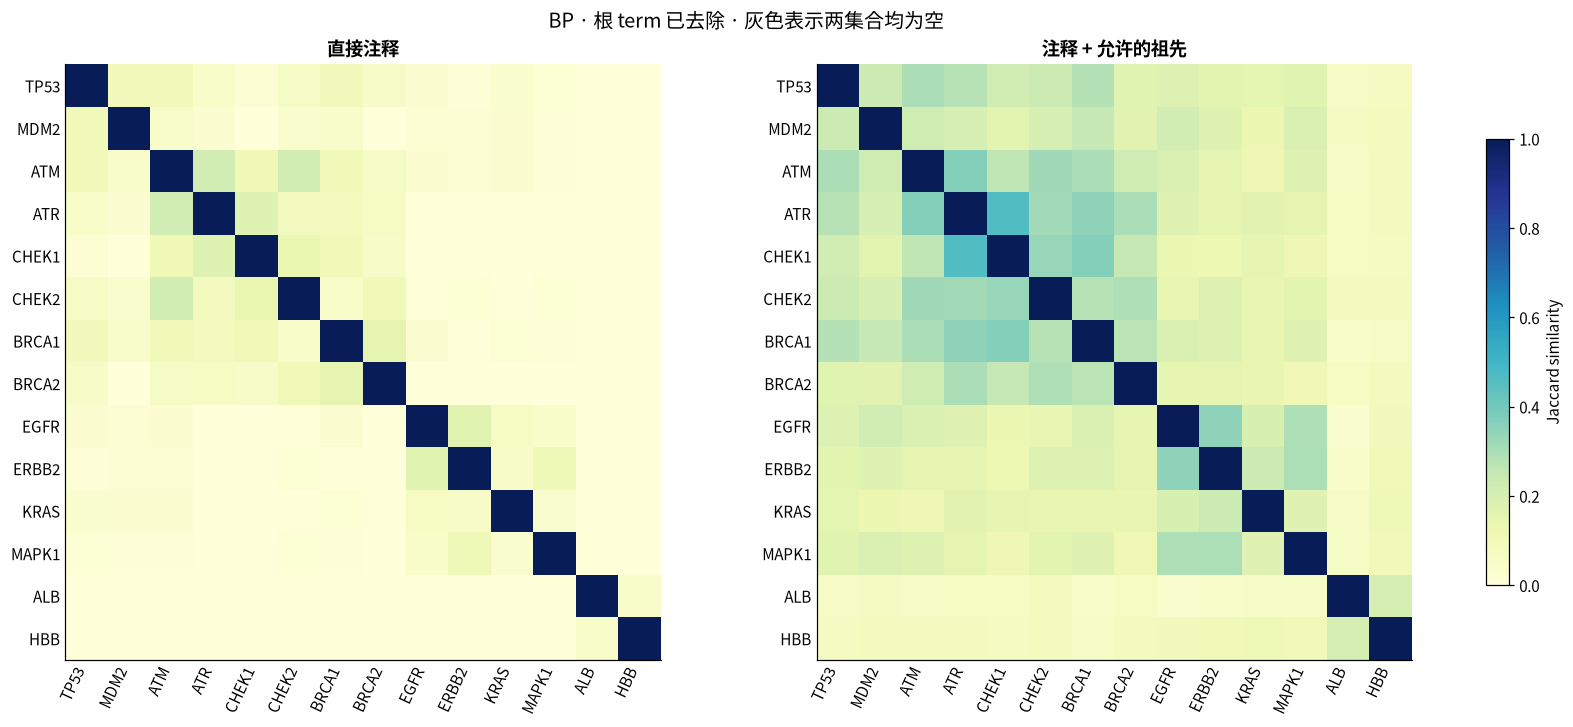

,object_id,symbol,direct_terms,propagated_terms
0,UniProtKB:P04637,TP53,74,330
1,UniProtKB:Q00987,MDM2,58,267
2,UniProtKB:Q13315,ATM,62,338
3,UniProtKB:Q13535,ATR,29,149
4,UniProtKB:O14757,CHEK1,18,103
5,UniProtKB:O96017,CHEK2,24,140
6,UniProtKB:P38398,BRCA1,35,207
7,UniProtKB:P51587,BRCA2,19,130
8,UniProtKB:P00533,EGFR,41,220
9,UniProtKB:P04626,ERBB2,36,179


**TP53 在此面板内的相似邻居**

,object_id,symbol,direct_jaccard,propagated_jaccard
0,UniProtKB:Q13315,ATM,0.096774,0.299611
1,UniProtKB:P38398,BRCA1,0.090000,0.284689
2,UniProtKB:Q13535,ATR,0.051020,0.280749
3,UniProtKB:O96017,CHEK2,0.065217,0.233596
4,UniProtKB:Q00987,MDM2,0.100000,0.230928
5,UniProtKB:O14757,CHEK1,0.022222,0.212885
6,UniProtKB:P00533,EGFR,0.026786,0.180258
7,UniProtKB:P51587,BRCA2,0.056818,0.167513


In [9]:
panel_ids = [
    "UniProtKB:P04637", "UniProtKB:Q00987",  # TP53, MDM2
    "UniProtKB:Q13315", "UniProtKB:Q13535",  # ATM, ATR
    "UniProtKB:O14757", "UniProtKB:O96017",  # CHEK1, CHEK2
    "UniProtKB:P38398", "UniProtKB:P51587",  # BRCA1, BRCA2
    "UniProtKB:P00533", "UniProtKB:P04626",  # EGFR, ERBB2
    "UniProtKB:P01116", "UniProtKB:P28482",  # KRAS, MAPK1
    "UniProtKB:P02768", "UniProtKB:P68871",  # ALB, HBB
]
panel_ids = list(dict.fromkeys([EXAMPLE_OBJECT_ID, *panel_ids]))
assert all(key in objects for key in panel_ids), "某个面板 ID 不在当前 GAF 中。"

@lru_cache(maxsize=None)
def term_ancestors(term_id):
    return frozenset(ontology.ancestors(term_id))

def propagate(term_ids):
    expanded = set(term_ids)
    for term_id in term_ids:
        expanded.update(term_ancestors(term_id))
    return expanded - ROOT_IDS

direct_sets = {key: projection_memberships.get(key, set()) - ROOT_IDS for key in panel_ids}
propagated_sets = {key: propagate(direct_sets[key]) for key in panel_ids}
assert all(direct_sets[key] <= propagated_sets[key] for key in panel_ids)
assert all(not (terms & ROOT_IDS) for terms in propagated_sets.values())

def similarity_matrix(sets):
    return np.array([[np.nan if (score := jaccard(sets[a], sets[b])) is None else score
                      for b in panel_ids] for a in panel_ids])

direct_similarity = similarity_matrix(direct_sets)
propagated_similarity = similarity_matrix(propagated_sets)
for matrix in (direct_similarity, propagated_similarity):
    assert np.allclose(matrix, matrix.T, equal_nan=True)
labels = [objects[key] for key in panel_ids]
fig, axes = plt.subplots(1, 2, figsize=(15, 6.5), layout="constrained")
cmap = plt.get_cmap("YlGnBu").copy()
cmap.set_bad("#E4E6E8")
for ax, matrix, title in [(axes[0], direct_similarity, "直接注释"), (axes[1], propagated_similarity, "注释 + 允许的祖先")]:
    image = ax.imshow(matrix, cmap=cmap, vmin=0, vmax=1)
    ax.set_xticks(range(len(labels)), labels=labels, rotation=65, ha="right")
    ax.set_yticks(range(len(labels)), labels=labels)
    ax.set_title(title)
    ax.tick_params(length=0)
fig.colorbar(image, ax=axes, shrink=0.75, label="Jaccard similarity")
fig.suptitle(f"{ASPECTS[SIMILARITY_ASPECT]} · 根 term 已去除 · 灰色表示两集合均为空", fontsize=13)
save_figure(fig, "07_direct_vs_propagated_similarity")
panel_table = pd.DataFrame([{"object_id": key, "symbol": objects[key], "direct_terms": len(direct_sets[key]),
                             "propagated_terms": len(propagated_sets[key])} for key in panel_ids])
display(panel_table)
query_index = panel_ids.index(EXAMPLE_OBJECT_ID)
rank_rows = [{"object_id": key, "symbol": objects[key],
              "direct_jaccard": direct_similarity[query_index, i],
              "propagated_jaccard": propagated_similarity[query_index, i]}
             for i, key in enumerate(panel_ids) if key != EXAMPLE_OBJECT_ID]
neighbor_table = pd.DataFrame(rank_rows).sort_values("propagated_jaccard", ascending=False, na_position="last")
display(Markdown(f"**{example_name} 在此面板内的相似邻居**"))
display(neighbor_table.head(8).reset_index(drop=True))
panel_table.to_csv(OUT / "similarity_panel.csv", index=False)
neighbor_table.to_csv(OUT / "example_neighbors.csv", index=False)
pd.DataFrame(direct_similarity, index=panel_ids, columns=panel_ids).to_csv(OUT / "direct_jaccard.csv")
pd.DataFrame(propagated_similarity, index=panel_ids, columns=panel_ids).to_csv(OUT / "propagated_jaccard.csv")

## 9 · 对本项目意味着什么？

把本 notebook 当作增广前的知识快照。下一步可以针对任务说明，确定外部知识的检索重点：

| 所见现象 | 可以提出的知识需求 | 后续独立评价 |
|---|---|---|
| 某些对象的 BP 覆盖较少 | 检索它们参与的过程、通路及功能模块 | 扰动响应预测与功能邻居 |
| 调控关系与分类关系承担不同语义 | 在情境层补充有方向的活动联系 | 有符号响应及组合扰动 |
| 祖先传播改变相似度 | 明确固定的传播和投影规则 | 比较表示与独立实验 profile 的一致性 |
| 一条 pair 有多条记录 | 保留证据与出处，明确去重单位 | 分证据来源评价增广 |

**任务说明 → 知识需求 → 外部证据整合 → 冻结增广 → 下游评测。**
下游分数用于评价产物；agent 依照任务类别、生物学证据和关系语义选择增广内容。

In [10]:
summary = {
    "go_release": manifest["ontology"]["release"],
    "active_terms": len(active), "annotation_records": total_records,
    "unique_db_object_ids": len(objects), "not_records": sum(negative_counts.values()),
    "multiple_is_a_parents": multi_parent,
    "median_positive_terms_per_object": float(coverage.positive_terms.median()),
    "example_object_id": EXAMPLE_OBJECT_ID, "example_symbol": example_name,
    "similarity_aspect": SIMILARITY_ASPECT, "projection_relations": sorted(PROJECTION_RELATIONS),
    "evidence_filter": None if EVIDENCE_CODES is None else sorted(EVIDENCE_CODES),
    "root_terms_excluded": sorted(ROOT_IDS),
    "knowledge_augmentation_performed": False,
}
(OUT / "overview_summary.json").write_text(json.dumps(summary, ensure_ascii=False, indent=2) + "\n")
versions = {"python": sys.version.split()[0], "numpy": np.__version__, "pandas": pd.__version__,
            "matplotlib": plt.matplotlib.__version__, "networkx": nx.__version__}
(OUT / "runtime_versions.json").write_text(json.dumps(versions, indent=2) + "\n")
display(Markdown(
    f"**本次运行：** {len(active):,} 个有效 term，{total_records:,} 条记录；"
    f"非根 term 中 {multi_parent / (len(active) - 3):.1%} 有多个 is_a parent；"
    f"每个已出现对象的不同正注释 term 中位数为 {coverage.positive_terms.median():g}。\n\n"
    "图表及 CSV 已保存到 `outputs/notebooks/01_go_overview/`。"
))

**本次运行：** 38,092 个有效 term，910,476 条记录；非根 term 中 38.5% 有多个 is_a parent；每个已出现对象的不同正注释 term 中位数为 4。

图表及 CSV 已保存到 `outputs/notebooks/01_go_overview/`。

## 继续阅读

- 项目内：[GO 基础](../docs/go_foundations.md) · [真实数据快照](../docs/data_snapshot.md) · [评测设计](../docs/evaluation.md)
- 官方：[GO overview](https://geneontology.org/docs/ontology-documentation/) · [关系语义](https://geneontology.org/docs/ontology-relations/) · [GAF 2.2](https://geneontology.org/docs/go-annotation-file-gaf-format-2.2/) · [证据代码](https://geneontology.org/docs/guide-go-evidence-codes/)
- 下游应用：[GEARS](https://www.nature.com/articles/s41587-023-01905-6)

本 notebook 的集合相似度用于解释 GO 派生表示；尚未调用 GEARS 的预处理或训练代码。